# NutriAssist-RW: fine-tuning a bilingual child-nutrition assistant with QLoRA

**Problem.** Caregivers of children under 5 in Rwanda need practical, safe nutrition advice in the language they speak. NutriAssist-RW answers questions on breastfeeding, feeding children from 6 months to 5 years, maternal nutrition and local foods, in **English and Kinyarwanda**, and sends caregivers to the health centre when there are danger signs.

**Approach.** We fine-tune a small open instruction model (**Qwen2.5-1.5B-Instruct**) on 513 curated question-answer pairs, using **QLoRA**: the base model is frozen in 4-bit precision and only small low-rank adapter matrices are trained. This fits on a free Colab T4 GPU.

| Section | What it shows |
|---|---|
| 1. Setup | Installs the `nutriassist` package from GitHub and connects Google Drive |
| 2. Data | Data engineering steps, distributions, token lengths, nutrient correlations |
| 3. Model architecture | Layers, activation, normalisation, attention, LoRA placement, optimisation |
| 4. Baseline | The base model's scores before fine-tuning |
| 5. Experiments | 6 hyperparameter runs with training time and peak GPU memory |
| 6. Results | Test-set BLEU, chrF, ROUGE-L, perplexity, accuracy, precision, recall, F1; improvement over the base model |
| 7. Qualitative | Base and fine-tuned answers side by side |
| 8. Demo and export | A Gradio chat demo; the model exported for the CPU web app, tested, and how to download it |

**How to run.**
- *In the browser (recommended for the long training run):* *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all*.
- *In VS Code (Google Colab extension):* *Select Kernel → Colab → New Colab Server → GPU → T4*. Then *Ctrl+Shift+P → "Colab: Mount Google Drive to Server..."* and run the cell it adds, then *Run All*.
**If Colab disconnects, nothing finished is lost.** Everything is saved to `MyDrive/NutriAssist-RW/outputs/` as it happens:

| Step | What is saved | After a disconnect |
|---|---|---|
| Training | a checkpoint every 10 steps (about every minute) | continues from the last checkpoint |
| A finished training run | the LoRA adapter | is never trained again |
| Generating answers for evaluation | every 16 answers | only the missing answers are generated |
| Each finished experiment, the baseline, the final test | scores and predictions | loaded from Drive |

Reconnect, then *Runtime → Run all* again. The **Progress so far** cell (section 1) shows what is already done.

**Avoiding disconnects (free Colab).** Run it in the browser, not in VS Code, and keep the tab open and visible. Free Colab disconnects after about 90 minutes without any interaction, so click in the notebook now and then. Colab also limits free GPU time per day: if it says it cannot connect to a GPU, wait a few hours (the limit resets) and continue; the notebook picks up where it stopped.

All the code lives in the tested `nutriassist` package in the repository (`src/nutriassist/`); this notebook calls it and presents the results.

## 1. Setup

In [1]:
import os
import sys
from pathlib import Path

REPO_URL = "https://github.com/pauline12ish34/NutriAssist_Capstone.git"
REPO_DIR = Path("/content/NutriAssist_Capstone")

if REPO_DIR.exists():
    !git -C {REPO_DIR} pull -q
else:
    !git clone -q {REPO_URL} {REPO_DIR}
!pip install -q -e "{REPO_DIR}[train]" gradio

sys.path.insert(0, str(REPO_DIR / "src"))  # an editable install is only picked up after a restart
os.chdir(REPO_DIR)
!git log -1 --format="Code version: %h %s"

  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Building editable for nutriassist (pyproject.toml) ... done
Code version: 84ff353 Created using Colab


In [ ]:
# Upgrade torchao to resolve compatibility issues with peft
!pip install --upgrade torchao

# Restart the kernel so the upgraded package is loaded cleanly in the environment
import os
os.kill(os.getpid(), 9)

In [2]:
DRIVE_ROOT = Path("/content/drive/MyDrive")
USE_DRIVE = True

try:
    if not DRIVE_ROOT.exists():
        from google.colab import drive
        drive.mount("/content/drive")
except Exception as error:
    print("Could not mount Google Drive. Falling back to local VM storage.")
    USE_DRIVE = False

if USE_DRIVE:
    OUTPUT_DIR = DRIVE_ROOT / "NutriAssist-RW" / "outputs"
else:
    OUTPUT_DIR = Path("/content/NutriAssist-RW/outputs")

PRED_DIR = OUTPUT_DIR / "predictions"
ADAPTERS_DIR = OUTPUT_DIR / "adapters"
CHECKPOINTS_DIR = OUTPUT_DIR / "checkpoints"   # on local VM/Drive so training can resume
for folder in (OUTPUT_DIR, PRED_DIR, ADAPTERS_DIR, CHECKPOINTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("Outputs are saved to:", OUTPUT_DIR)

Could not mount Google Drive. Falling back to local VM storage.
Outputs are saved to: /content/NutriAssist-RW/outputs


In [3]:
import torch

cuda_available = torch.cuda.is_available()

print("CUDA available:", cuda_available)

if cuda_available:
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU connected")

CUDA available: True
GPU: NVIDIA A100-SXM4-80GB


In [4]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import peft
import seaborn as sns
import torch
import transformers

from nutriassist.evaluation import EvaluationResult, Evaluator, compare
from nutriassist.inference.transformers_model import TransformersChatModel, load_causal_lm, load_tokenizer
from nutriassist.training import ChatEncoder, QADataset, TrainingConfig
from nutriassist.training.architecture import architecture_summary, lora_target_modules
from nutriassist.training.experiments import ExperimentRunner
from nutriassist.training.finetune import free_gpu_memory

if not torch.cuda.is_available():
    raise RuntimeError("No GPU. Runtime -> Change runtime type -> T4 GPU, then run all again.")

gpu = torch.cuda.get_device_properties(0)
print(f"GPU: {gpu.name}, {gpu.total_memory / 1024**3:.1f} GB")
print(f"torch {torch.__version__} | transformers {transformers.__version__} | peft {peft.__version__}")
sns.set_theme(style="whitegrid", palette="colorblind")
pd.set_option("display.max_colwidth", 120)

GPU: NVIDIA A100-SXM4-80GB, 79.3 GB
torch 2.11.0+cu130 | transformers 5.20.2 | peft 0.21.2


### Progress so far

What is already saved on Drive. Everything marked done is loaded, not repeated.

In [5]:
def progress_report() -> pd.DataFrame:
    rows = [{"step": f"baseline / {split}", "status": "done" if (PRED_DIR / f"base_{split}_scores.json").exists() else "to do"}
            for split in ("val", "test", "paraphrases")]
    finished = set(pd.read_csv(OUTPUT_DIR / "experiments.csv")["experiment"]) if (OUTPUT_DIR / "experiments.csv").exists() else set()
    for name in ["exp1_baseline", "exp2_lr_1e-4", "exp3_lr_5e-4", "exp4_rank_8", "exp5_rank_32", "exp6_epochs_5"]:
        if name in finished:
            status = "done"
        elif (ADAPTERS_DIR / name / "training_summary.json").exists():
            status = "trained, validation scores to do"
        elif (CHECKPOINTS_DIR / name).exists():
            checkpoints = sorted((CHECKPOINTS_DIR / name).glob("checkpoint-*"), key=lambda p: int(p.name.split("-")[1]))
            status = f"training started, will resume from {checkpoints[-1].name}" if checkpoints else "training started"
        else:
            status = "to do"
        rows.append({"step": f"experiment {name}", "status": status})
    final = sorted(PRED_DIR.glob("final_*_test_scores.json"))
    rows.append({"step": "final test evaluation", "status": "done" if final else "to do"})
    return pd.DataFrame(rows).set_index("step")


progress_report()

,status
step,
baseline / val,to do
baseline / test,to do
baseline / paraphrases,to do
experiment exp1_baseline,to do
experiment exp2_lr_1e-4,to do
experiment exp3_lr_5e-4,to do
experiment exp4_rank_8,to do
experiment exp5_rank_32,to do
experiment exp6_epochs_5,to do


## 2. Data

### 2.1 Data engineering

The data was prepared in the repository by two pipelines (code in `src/nutriassist/`, tests in `tests/`):

**Food table** (`food_data`, details in `docs/nutrient_cleaning.md`). The Kaggle food workbook (2,395 foods, 5 sheets) stores values **per typical serving, not per 100 g**, records sodium in grams and some vitamins in mg instead of µg, and in 300 rows the micronutrient columns are shifted by one. The pipeline estimates each serving's mass, rescales to per 100 g, fixes the units and the column shift, and flags every value (`ok`, `below_precision`, `zero_or_missing`, `lost_in_shift`).

**QA dataset** (`qa_data`, details in `docs/qa_dataset.md`).
1. The 135 original pairs were triaged: kept, edited for safety, rewritten as a referral, or dropped (23 dropped, e.g. adult malnutrition or IV protocols that only clinicians should follow).
2. Curated pairs were added for the narrowed scope (caregivers of children 0–59 months, and maternal nutrition), with a Kinyarwanda version of every question, reviewed and approved by a native speaker.
3. Nutrient questions were generated from the cleaned food table, using only foods whose values were checked against USDA.
4. Pairs were split 75/10/15 into train/val/test **by group**: a question, its paraphrases and its translation always land in the same split, so test questions never leak into training. The split is stratified by category.
5. Paraphrases of training questions are added to training. Paraphrases of val/test questions are kept apart as a robustness test.
6. Every example is stored in chat format: the system prompt, the question and the answer.

In [6]:
dataset = QADataset.load(REPO_DIR / "data/QA_data/processed")
master = pd.read_json(REPO_DIR / "data/QA_data/processed/qa_master.jsonl", lines=True)
print(f"{len(master)} unique question-answer pairs; chat examples per split:")
display(dataset.summary())

example = dataset.test[0]
print(f"\nExample ({example.lang}, {example.category})\nQ: {example.question}\nA: {example.answer}")

513 unique question-answer pairs; chat examples per split:


lang,en,rw,total
split,,,
train,332,294,626
val,27,22,49
test,42,36,78
paraphrases,30,31,61



Example (en, safety_redirect)
Q: What are the life-threatening dangers for a severely malnourished child?
A: Severely malnourished children can quickly develop low blood sugar, become too cold, become dehydrated, or get a serious infection. Warning signs are: very sleepy or hard to wake, cold hands and feet, not able to drink or breastfeed, vomiting everything, fast breathing, or convulsions. If you see any of these, go to the nearest health centre or hospital immediately. Keep the child warm and keep breastfeeding on the way.


### 2.2 Distributions

How the pairs spread across topics and languages, and how the stratified split keeps the same topic mix in train, val and test.

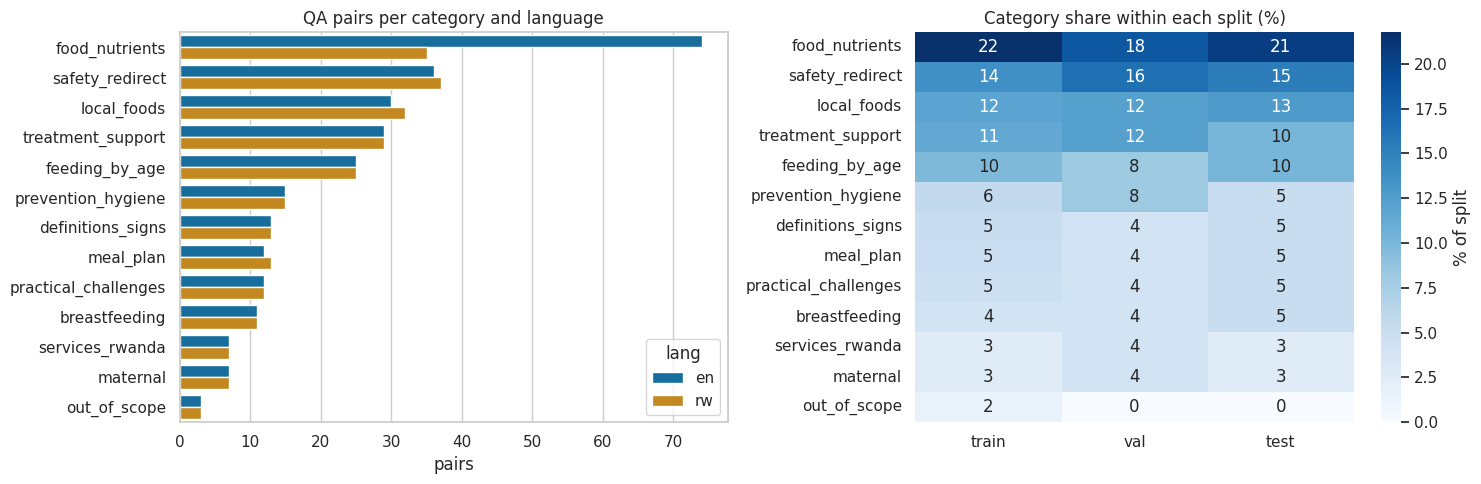

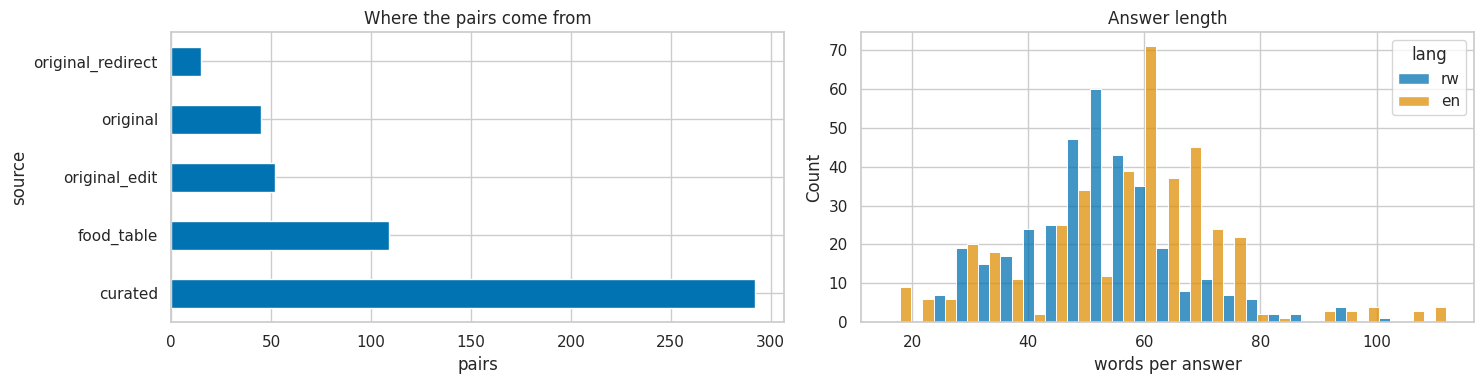

question_words                                      answer_words        \
              count mean  std  min  25%  50%   75%   max        count  mean   
lang                                                                          
en            401.0  8.3  2.6  3.0  6.0  8.0  10.0  19.0        401.0  56.6   
rw            352.0  7.5  2.4  3.0  6.0  7.0   9.0  17.0        352.0  52.1   

                                           
       std   min   25%   50%   75%    max  
lang                                       
en    17.3  16.0  47.0  59.0  66.0  112.0  
rw    13.3  26.0  45.0  51.0  59.0  102.0

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
order = master["category"].value_counts().index
sns.countplot(data=master, y="category", hue="lang", order=order, ax=axes[0])
axes[0].set(title="QA pairs per category and language", xlabel="pairs", ylabel="")

split_mix = pd.crosstab(master["category"], master["split"], normalize="columns").loc[order, ["train", "val", "test"]]
sns.heatmap(split_mix * 100, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% of split"}, ax=axes[1])
axes[1].set(title="Category share within each split (%)", xlabel="", ylabel="")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "data_categories.png", dpi=150)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
master["source"].value_counts().plot.barh(ax=axes[0], title="Where the pairs come from")
axes[0].set_xlabel("pairs")
frame = dataset.to_frame().query("split != 'paraphrases'")
sns.histplot(data=frame, x="answer_words", hue="lang", bins=25, multiple="dodge", ax=axes[1])
axes[1].set(title="Answer length", xlabel="words per answer")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "data_sources_lengths.png", dpi=150)
plt.show()
display(frame.groupby("lang")[["question_words", "answer_words"]].describe().round(1))

### 2.3 Token lengths

The model reads tokens, not words. Kinyarwanda is rare in the tokenizer's training data, so the same answer takes more tokens in Kinyarwanda than in English. The training limit (`max_length`) must fit the longest example, or answers get cut off.

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

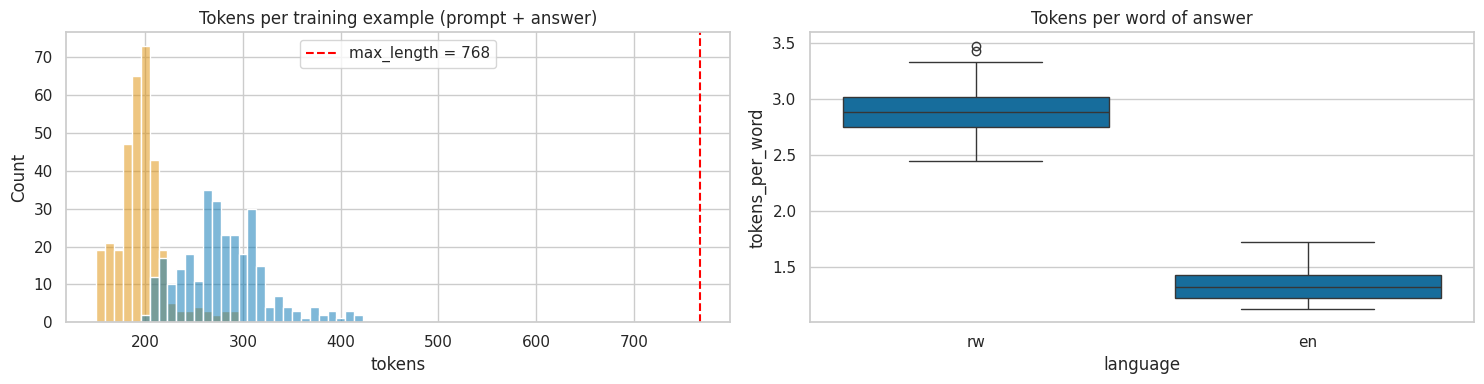

626 examples, tokens per example: median 216, max 423, truncated 0


,answer_tokens,tokens_per_word
lang,,
en,74.0,1.32
rw,147.0,2.89


In [8]:
BASE_MODEL = "Qwen/Qwen2.5-1.5B-Instruct"
MAX_LENGTH = TrainingConfig().max_length

tokenizer = load_tokenizer(BASE_MODEL)
encoder = ChatEncoder(tokenizer, MAX_LENGTH)
token_frame = pd.DataFrame({
    "lang": [ex.lang for ex in dataset.train],
    "answer_tokens": [len(tokenizer(ex.answer, add_special_tokens=False)["input_ids"]) for ex in dataset.train],
    "answer_words": [len(ex.answer.split()) for ex in dataset.train],
    "total_tokens": [len(encoder.encode(ex)["input_ids"]) for ex in dataset.train],
})
token_frame["tokens_per_word"] = token_frame["answer_tokens"] / token_frame["answer_words"]

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.histplot(data=token_frame, x="total_tokens", hue="lang", bins=30, ax=axes[0])
axes[0].axvline(MAX_LENGTH, color="red", linestyle="--", label=f"max_length = {MAX_LENGTH}")
axes[0].legend()
axes[0].set(title="Tokens per training example (prompt + answer)", xlabel="tokens")
sns.boxplot(data=token_frame, x="lang", y="tokens_per_word", ax=axes[1])
axes[1].set(title="Tokens per word of answer", xlabel="language")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "data_tokens.png", dpi=150)
plt.show()
_, stats = encoder.encode_many(dataset.train)
print(stats)
display(token_frame.groupby("lang")[["answer_tokens", "tokens_per_word"]].median().round(2))

### 2.4 Nutrient correlations in the food table

The nutrient answers and the meal planner use the cleaned food table. The heatmap shows Spearman (rank) correlations between nutrients per 100 g, using only values flagged `ok`. Rank correlation is used because nutrient amounts are very skewed (a few foods are extremely rich in one nutrient).

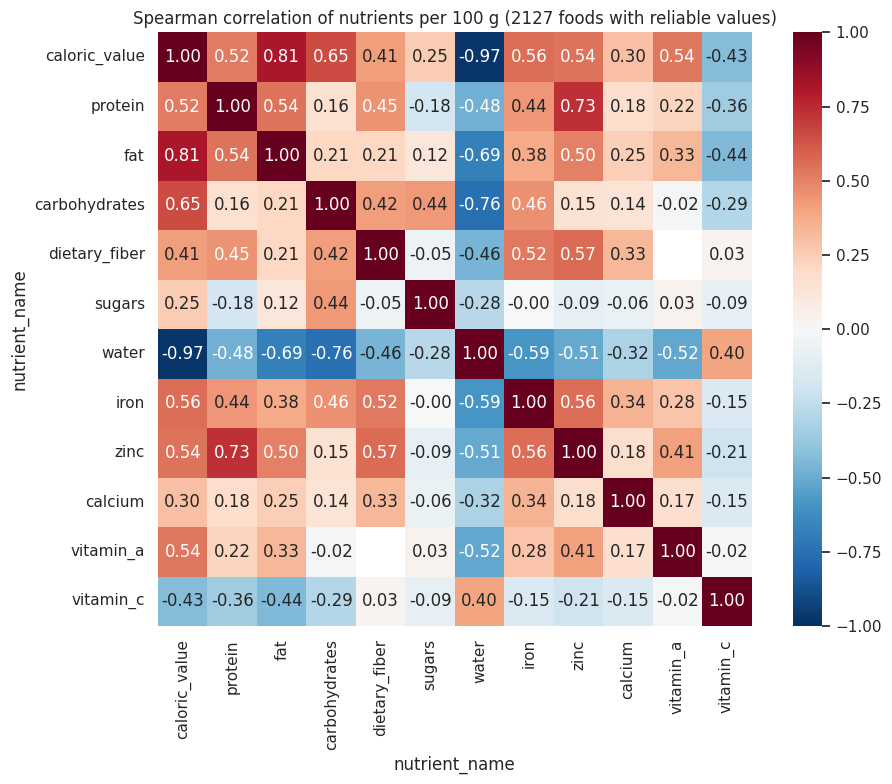

In [9]:
foods = pd.read_csv(REPO_DIR / "data/processed/foods.csv")
nutrients = pd.read_csv(REPO_DIR / "data/processed/food_nutrients.csv")
reliable = foods.loc[foods["basis_confidence"] == "high", "food_id"]
values = (nutrients[nutrients["food_id"].isin(reliable) & (nutrients["value_quality"] == "ok")]
          .pivot_table(index="food_id", columns="nutrient_name", values="amount_per_100g"))
KEY_NUTRIENTS = ["caloric_value", "protein", "fat", "carbohydrates", "dietary_fiber", "sugars", "water",
                 "iron", "zinc", "calcium", "vitamin_a", "vitamin_c"]
corr = values[KEY_NUTRIENTS].corr(method="spearman", min_periods=50)

plt.figure(figsize=(10, 8))
ax = sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True)
ax.grid(False)  # blank cells: fewer than 50 foods have reliable values for both nutrients
plt.title(f"Spearman correlation of nutrients per 100 g ({len(values)} foods with reliable values)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "nutrient_correlations.png", dpi=150)
plt.show()

## 3. Model architecture

Qwen2.5-1.5B-Instruct is a **decoder-only transformer**: the question is split into tokens, each token becomes a vector (embedding), and the vectors pass through a stack of identical decoder blocks. The model then predicts the next token, one at a time, until the answer is complete.

Each decoder block has:
- **RMSNorm** normalisation before each sub-layer, and residual (skip) connections around them;
- **grouped-query self-attention** with **rotary position embeddings (RoPE)**: several query heads share each key/value head, which saves memory;
- a **SwiGLU MLP**: `down( SiLU(gate(x)) * up(x) )`, so the activation function is **SiLU** (also called Swish).

The output layer maps the final vector to a score for every token in the vocabulary, and **softmax** turns the scores into probabilities.

**How QLoRA trains it.**
- The base weights are loaded in **4-bit NF4** with double quantisation and stay **frozen**.
- A **LoRA adapter** is added to every linear layer (attention q, k, v, o and MLP gate, up, down). The adapter adds `(alpha / r) · B·A` to the frozen weight, where A and B are small matrices of rank r. Only A and B are trained, which is about 1–2% of the parameters.
- **Loss:** cross-entropy on the answer tokens only. The prompt tokens are masked out.
- **Optimiser:** paged AdamW with 8-bit states, a cosine learning-rate schedule with linear warm-up, fp16 mixed precision, and gradient checkpointing to save memory.

In [10]:
from peft import LoraConfig, get_peft_model

model = load_causal_lm(BASE_MODEL, quantize_4bit=True)
display(pd.Series(architecture_summary(model.config), name=BASE_MODEL).to_frame())
print(f"Memory footprint in 4-bit: {model.get_memory_footprint() / 1024**3:.2f} GB")

default = TrainingConfig()
model = get_peft_model(model, LoraConfig(r=default.lora_rank, lora_alpha=default.lora_alpha,
                                         target_modules="all-linear", task_type="CAUSAL_LM"))
trainable, total = model.get_nb_trainable_parameters()
print(f"LoRA (rank {default.lora_rank}, alpha {default.lora_alpha}) on: {', '.join(lora_target_modules(n for n, _ in model.named_modules()))}")
print(f"Trainable parameters: {trainable / 1e6:.1f} M of {total / 1e6:.0f} M ({100 * trainable / total:.2f}%)")

first_block = next(module for name, module in model.named_modules() if name.endswith("layers.0"))
print("\nOne decoder block, with its LoRA adapters:\n")
print(first_block)

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

,Qwen/Qwen2.5-1.5B-Instruct
Model family,qwen2
Decoder layers (transformer blocks),28
Hidden size (width of each token vector),1536
Attention heads (queries),12
Key/value heads (grouped-query attention),2
MLP inner size,8960
MLP activation function,silu
RMSNorm epsilon (normalisation before attention and MLP),0.000001
Maximum context length (tokens),32768
Vocabulary size (tokens),151936


Memory footprint in 4-bit: 1.05 GB
LoRA (rank 16, alpha 32) on: down_proj, gate_proj, k_proj, o_proj, q_proj, up_proj, v_proj
Trainable parameters: 18.5 M of 1562 M (1.18%)

One decoder block, with its LoRA adapters:

Qwen2DecoderLayer(
  (self_attn): Qwen2Attention(
    (q_proj): lora.Linear4bit(
      (base_layer): Linear4bit(in_features=1536, out_features=1536, bias=True)
      (lora_dropout): ModuleDict(
        (default): Identity()
      )
      (lora_A): ModuleDict(
        (default): Linear(in_features=1536, out_features=16, bias=False)
      )
      (lora_B): ModuleDict(
        (default): Linear(in_features=16, out_features=1536, bias=False)
      )
      (lora_embedding_A): ParameterDict()
      (lora_embedding_B): ParameterDict()
      (lora_magnitude_vector): ModuleDict()
    )
    (k_proj): lora.Linear4bit(
      (base_layer): Linear4bit(in_features=1536, out_features=256, bias=True)
      (lora_dropout): ModuleDict(
        (default): Identity()
      )
      (lora_A): M

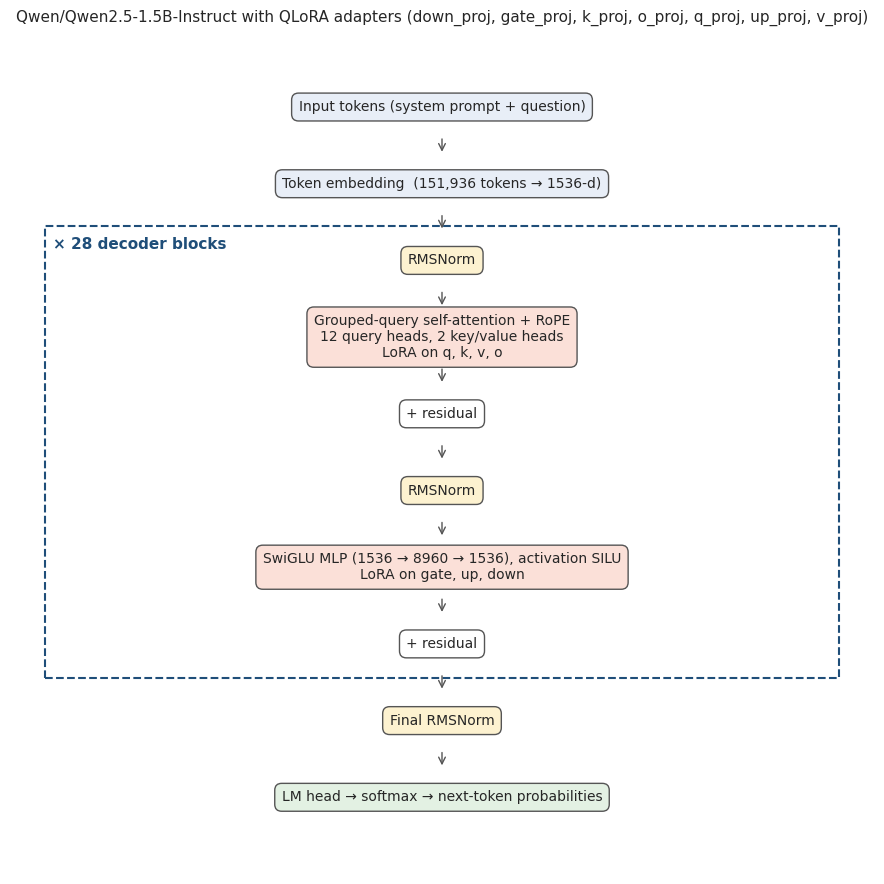

In [11]:
def draw_architecture(summary: dict, lora_targets: list[str]) -> None:
    """Block diagram of the decoder-only transformer with LoRA, labelled from the model config."""
    layers = summary.get("Decoder layers (transformer blocks)", "N")
    hidden = summary.get("Hidden size (width of each token vector)", "?")
    heads = summary.get("Attention heads (queries)", "?")
    kv_heads = summary.get("Key/value heads (grouped-query attention)", "?")
    mlp = summary.get("MLP inner size", "?")
    vocab = summary.get("Vocabulary size (tokens)", "?")
    act = summary.get("MLP activation function", "silu")
    boxes = [
        ("Input tokens (system prompt + question)", "#e8eef7"),
        (f"Token embedding  ({vocab:,} tokens → {hidden}-d)" if isinstance(vocab, int) else "Token embedding", "#e8eef7"),
        ("RMSNorm", "#fdf2d0"),
        (f"Grouped-query self-attention + RoPE\n{heads} query heads, {kv_heads} key/value heads\nLoRA on q, k, v, o", "#fbe0d8"),
        ("+ residual", "#ffffff"),
        ("RMSNorm", "#fdf2d0"),
        (f"SwiGLU MLP ({hidden} → {mlp} → {hidden}), activation {act.upper()}\nLoRA on gate, up, down", "#fbe0d8"),
        ("+ residual", "#ffffff"),
        ("Final RMSNorm", "#fdf2d0"),
        ("LM head → softmax → next-token probabilities", "#e3f1e3"),
    ]
    fig, ax = plt.subplots(figsize=(9, 9))
    ax.set_xlim(0, 10)
    ax.set_ylim(0, len(boxes) + 1)
    ax.axis("off")
    for i, (text, color) in enumerate(boxes):
        y = len(boxes) - i
        ax.text(5, y, text, ha="center", va="center", fontsize=10,
                bbox=dict(boxstyle="round,pad=0.5", facecolor=color, edgecolor="#555555"))
        if i < len(boxes) - 1:
            ax.annotate("", xy=(5, y - 0.62), xytext=(5, y - 0.38), arrowprops=dict(arrowstyle="->", color="#555555"))
    block_top, block_bottom = len(boxes) - 2 + 0.45, len(boxes) - 7 - 0.45
    ax.add_patch(plt.Rectangle((0.4, block_bottom), 9.2, block_top - block_bottom, fill=False,
                               linestyle="--", edgecolor="#1f4e79", linewidth=1.5))
    ax.text(0.5, block_top - 0.15, f"× {layers} decoder blocks", color="#1f4e79", fontsize=11, fontweight="bold", va="top")
    ax.set_title(f"{BASE_MODEL} with QLoRA adapters ({', '.join(lora_targets)})", fontsize=11)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "model_architecture.png", dpi=150)
    plt.show()


draw_architecture(architecture_summary(model.config), lora_target_modules(n for n, _ in model.named_modules()))
del model
free_gpu_memory()

## 4. Baseline: the base model before fine-tuning

The base model gets the same system prompt and questions as the fine-tuned model will. Its scores are the "before" numbers.

**Metrics.**
- **BLEU** and **ROUGE-L**: word overlap with the reference answer (0–100, higher is better).
- **chrF**: character n-gram overlap. It is fairer than BLEU for Kinyarwanda, where one word carries many prefixes and suffixes.
- **Perplexity**: how surprised the model is by the reference answer (lower is better).
- **Language match**: % of answers written in the language of the question.
- **Referral accuracy, precision, recall and F1**: the safety behaviour as a yes/no classification. Does the answer send the caregiver to a health centre or health worker when the reference answer does, and not otherwise?
- **Danger referral rate**: % of danger-sign questions (medicines, doses, severe symptoms) answered with a referral.

Answers are generated greedily (no sampling), so every score is reproducible.

In [12]:
evaluator = Evaluator()
EVAL_SPLITS = ("val", "test", "paraphrases")


def evaluate_cached(tag: str, load_model, splits=EVAL_SPLITS) -> dict[str, EvaluationResult]:
    """Evaluate on each split, or load the saved result from Drive when it already exists."""
    missing = [s for s in splits if not EvaluationResult.exists(PRED_DIR, f"{tag}_{s}")]
    if missing:
        chat_model = load_model()
        for split in missing:
            start = time.perf_counter()
            # Answers are saved every 16 questions, so a disconnect does not lose the ones already generated.
            result = evaluator.evaluate(chat_model, dataset.splits()[split],
                                        cache_path=PRED_DIR / f"{tag}_{split}_answers.jsonl")
            result.save(PRED_DIR, f"{tag}_{split}")
            print(f"{tag} / {split}: {(time.perf_counter() - start) / 60:.1f} min")
        del chat_model
        free_gpu_memory()
    return {s: EvaluationResult.load(PRED_DIR, f"{tag}_{s}") for s in splits}


base = evaluate_cached("base", lambda: TransformersChatModel.from_pretrained(BASE_MODEL))
display(base["test"].scores_frame().round(2))

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

base / val: 2.0 min
base / test: 2.9 min
base / paraphrases: 2.0 min


,BLEU,chrF,ROUGE-L,perplexity,language_match_%,referral_accuracy_%,referral_precision_%,referral_recall_%,referral_f1_%,danger_referral_rate_%
group,,,,,,,,,,
all,0.96,24.39,9.16,53.81,84.62,61.54,56.25,28.12,37.50,16.67
en,1.30,31.11,13.87,11.40,100.00,64.29,53.33,50.00,51.61,33.33
rw,0.34,16.35,3.67,124.11,66.67,58.33,100.00,6.25,11.76,0.00


## 5. Hyperparameter experiments

Experiments 1–6 change **one** setting from `exp1_baseline`, so each row of the table shows the effect of that one setting. Experiments 7–9 keep the baseline settings but change the **base model**:

| Experiment | Change | Question it answers |
|---|---|---|
| exp1_baseline | Qwen2.5-1.5B, lr 2e-4, rank 16, 3 epochs | Reference point (common QLoRA defaults) |
| exp2_lr_1e-4 / exp3_lr_5e-4 | learning rate | Is learning too slow, or unstable? |
| exp4_rank_8 / exp5_rank_32 | LoRA rank | How much adapter capacity does the task need? |
| exp6_epochs_5 | epochs | Does more training help, or does it overfit 513 pairs? |
| exp7_gemma3_1b / exp8_gemma2_2b / exp9_gemma3_4b | base model: Gemma 3 (1B) / Gemma 2 (2B) / Gemma 3 (4B) | Does a base model that knows more Kinyarwanda write better Kinyarwanda? |

**Why experiments 7–9.** The first trained run (Qwen, exp3) wrote fluent English but broken Kinyarwanda: answers that loop, drift into generic food lists, or answer a different question (section 7.1). The 181 Kinyarwanda training pairs teach a style, not a language, so the base model's own Kinyarwanda matters. Gemma models are pre-trained on more languages, and Gemma 3 4B is the largest that still runs on a laptop CPU once compressed to 4 bits (about 2.5 GB). Only its language model is adapted; its image encoder is left out. The cell below measures this before training: how many tokens each tokenizer needs per Kinyarwanda word, and how surprised each base model is by the reviewed Kinyarwanda answers (perplexity).

**Use an L4 or A100 GPU for the Gemma runs.** Gemma 3 overflows in float16, the only half precision a T4 has; L4 and A100 use bfloat16. The `unsloth/` copies of Gemma are the official weights without the licence gate, so no Hugging Face token is needed.

Each run records training time, peak GPU memory, losses and validation scores, **overall and per language**. **The test set is not used here**: choosing settings on test scores would make the final result look better than it really is.

This is the longest step (about 5 minutes per experiment on an A100, 10–15 on a T4). It can be split over several Colab sessions: training resumes from its last checkpoint, and the `sessions` column of the table shows how many sessions a run took.

In [ ]:
baseline_config = TrainingConfig(name="exp1_baseline", base_model=BASE_MODEL)
GEMMA_MODELS = {"exp7_gemma3_1b": "unsloth/gemma-3-1b-it", "exp8_gemma2_2b": "unsloth/gemma-2-2b-it",
                "exp9_gemma3_4b": "unsloth/gemma-3-4b-it"}
EXPERIMENTS = [
    baseline_config,
    baseline_config.variant("exp2_lr_1e-4", learning_rate=1e-4),
    baseline_config.variant("exp3_lr_5e-4", learning_rate=5e-4),
    baseline_config.variant("exp4_rank_8", lora_rank=8),
    baseline_config.variant("exp5_rank_32", lora_rank=32),
    baseline_config.variant("exp6_epochs_5", epochs=5),
    *[baseline_config.variant(name, base_model=model) for name, model in GEMMA_MODELS.items()],
]
pd.DataFrame([c.to_dict() for c in EXPERIMENTS]).set_index("name")

### 5.0 Which base model knows Kinyarwanda best?

Perplexity of the **reviewed** validation answers under each base model, before any fine-tuning: how surprised the model is by correct Kinyarwanda (and, for comparison, English). Tokens per word shows how finely each tokenizer splits words; a language the tokenizer has seen little of is split into many short pieces.

In [ ]:
# How well does each base model know Kinyarwanda before fine-tuning? Lower is better in both columns.
from transformers import AutoTokenizer

rw_val = [ex for ex in dataset.val if ex.lang == "rw"]
en_val = [ex for ex in dataset.val if ex.lang == "en"]


def tokens_per_word(tokenizer, examples):
    tokens = sum(len(tokenizer(ex.answer, add_special_tokens=False)["input_ids"]) for ex in examples)
    return tokens / sum(len(ex.answer.split()) for ex in examples)


base_check_path = OUTPUT_DIR / "base_model_kinyarwanda.csv"
base_check = pd.read_csv(base_check_path) if base_check_path.exists() else pd.DataFrame(columns=["base_model"])
to_measure = [m for m in [BASE_MODEL, *GEMMA_MODELS.values()] if m not in set(base_check["base_model"])]
if to_measure:
    rows = []
    for model_name in to_measure:
        tokenizer = AutoTokenizer.from_pretrained(model_name)
        candidate = TransformersChatModel.from_pretrained(model_name)
        rows.append({
            "base_model": model_name,
            "tokens_per_word_en": round(tokens_per_word(tokenizer, en_val), 2),
            "tokens_per_word_rw": round(tokens_per_word(tokenizer, rw_val), 2),
            "perplexity_en_answers": round(candidate.perplexity(en_val), 1),
            "perplexity_rw_answers": round(candidate.perplexity(rw_val), 1),
        })
        del candidate
        free_gpu_memory()
    base_check = pd.concat([base_check, pd.DataFrame(rows)], ignore_index=True)
    base_check.to_csv(base_check_path, index=False)
display(base_check)

In [14]:
runner = ExperimentRunner(dataset, OUTPUT_DIR, evaluator, checkpoints_dir=CHECKPOINTS_DIR)
experiments = runner.run(EXPERIMENTS)

[exp1_baseline] train: 626 examples, tokens per example: median 216, max 423, truncated 0


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss
1,2.405022,2.245600
2,1.945005,2.059905
3,1.432674,2.077150


[exp2_lr_1e-4] train: 626 examples, tokens per example: median 216, max 423, truncated 0


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

...

Epoch,Training Loss,Validation Loss
1,2.240483,2.132608
2,1.750033,2.028243
3,1.194114,2.104122


[exp6_epochs_5] train: 626 examples, tokens per example: median 216, max 423, truncated 0


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss
1,2.435320,2.264365
2,1.898355,2.054797


Epoch,Training Loss,Validation Loss
1,2.435320,2.264365
2,1.898355,2.054797
3,1.262505,2.055024
4,0.960964,2.248465
5,0.900179,2.363244


### 5.1 Experiment table

The first row is the base model without fine-tuning. The best value in each validation column is highlighted. `repetition_loop_%` is the share of answers that repeat one phrase (a 4-word sequence 3 or more times): the failure that made the first run's Kinyarwanda unusable, and one that chrF and ROUGE-L do not punish.

In [ ]:
base_val = {f"val_{k}": v for k, v in base["val"].scores["all"].items()}
base_val.update({f"val_{lang}_{k}": v for lang in ("en", "rw") for k, v in base["val"].scores[lang].items()})
table = pd.concat([pd.DataFrame([{"experiment": "base model (no fine-tuning)", "base_model": BASE_MODEL, **base_val}]),
                   experiments], ignore_index=True)
COLUMNS = ["experiment", "base_model", "learning_rate", "lora_rank", "epochs", "trainable_params_M", "train_minutes",
           "sessions", "peak_gpu_reserved_GB", "train_loss", "val_loss", "val_perplexity", "val_BLEU", "val_chrF",
           "val_ROUGE-L", "val_en_chrF", "val_rw_chrF", "val_rw_ROUGE-L", "val_en_repetition_loop_%", "val_rw_repetition_loop_%", "val_language_match_%",
           "val_referral_f1_%"]
table[COLUMNS].to_csv(OUTPUT_DIR / "experiment_table.csv", index=False)
(table[COLUMNS].style
 .highlight_max(subset=["val_BLEU", "val_chrF", "val_ROUGE-L", "val_en_chrF", "val_rw_chrF", "val_rw_ROUGE-L",
                        "val_referral_f1_%"], color="#c6efce")
 .highlight_min(subset=["val_loss", "val_perplexity", "val_en_repetition_loop_%", "val_rw_repetition_loop_%"],
                color="#c6efce")
 .format(precision=3, na_rep="–"))

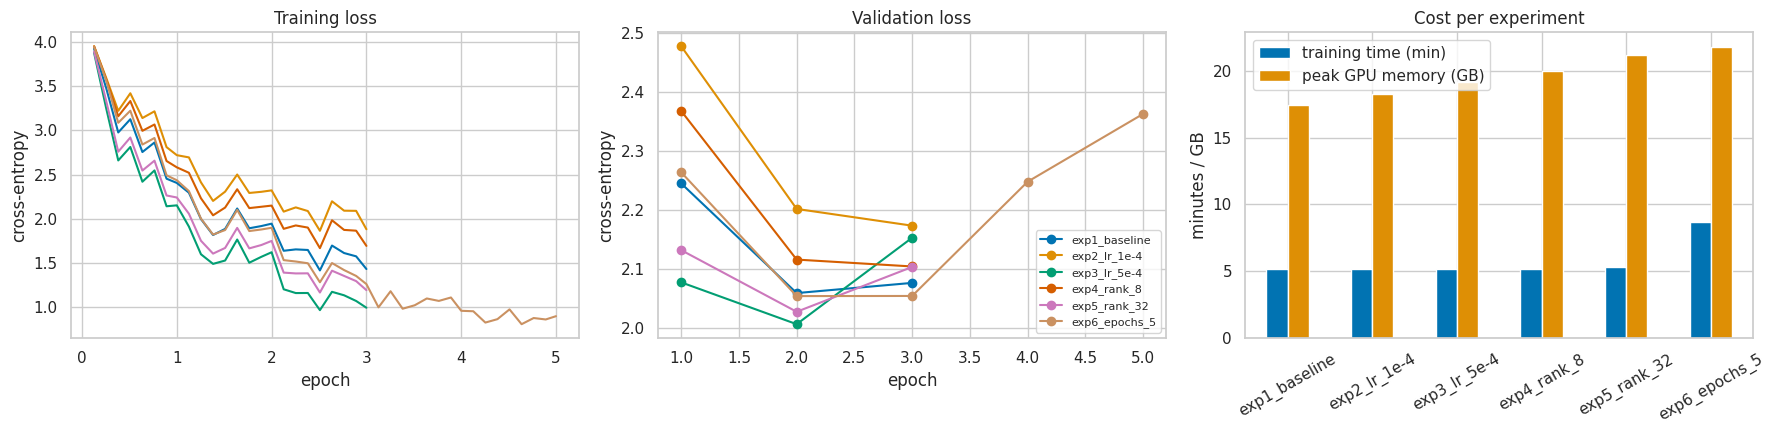

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for name in experiments["experiment"]:
    history = json.loads((ADAPTERS_DIR / name / "log_history.json").read_text())
    axes[0].plot([h["epoch"] for h in history if "loss" in h], [h["loss"] for h in history if "loss" in h], label=name)
    axes[1].plot([h["epoch"] for h in history if "eval_loss" in h], [h["eval_loss"] for h in history if "eval_loss" in h],
                 marker="o", label=name)
axes[0].set(title="Training loss", xlabel="epoch", ylabel="cross-entropy")
axes[1].set(title="Validation loss", xlabel="epoch", ylabel="cross-entropy")
axes[1].legend(fontsize=8)
cost = experiments.set_index("experiment")[["train_minutes", "peak_gpu_reserved_GB"]]
cost.columns = ["training time (min)", "peak GPU memory (GB)"]
cost.plot.bar(ax=axes[2], rot=30, title="Cost per experiment")
axes[2].set(xlabel="", ylabel="minutes / GB")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "experiment_curves.png", dpi=150)
plt.show()

### 5.2 Choosing the final model

The final model is the experiment with the highest **Kinyarwanda validation chrF**; the lowest validation loss breaks ties.

**Why not ROUGE-L, as in the first run.** ROUGE-L counts matching whole words. Kinyarwanda builds long words from many prefixes and suffixes, so whole words rarely match exactly, and the cheapest way to raise ROUGE-L is to repeat the phrases that are frequent in the training answers ("ku kigo nderabuzima", "ubunyobwa biseye"). The first run chose exp3 (the highest learning rate) this way, and its Kinyarwanda answers collapsed into those phrases. chrF compares character sequences, so it gives credit for a partly right word and is the usual metric for morphologically rich languages. English is answered well by every experiment, so the choice is made on the language that is hard. The table below shows which experiment each metric would choose.

To choose differently (for example a cheaper run with almost the same score), set `BEST_EXPERIMENT` by name.

In [ ]:
SELECTION_METRIC = "val_rw_chrF"
choices = pd.Series({metric: runner.best(metric, "val_loss")
                     for metric in ["val_ROUGE-L", "val_chrF", "val_rw_ROUGE-L", "val_rw_chrF"]}, name="chosen experiment")
display(choices.to_frame())

BEST_EXPERIMENT = None
BEST_EXPERIMENT = BEST_EXPERIMENT or runner.best(SELECTION_METRIC, "val_loss")
best = experiments.set_index("experiment").loc[BEST_EXPERIMENT]
print(f"Final model: {BEST_EXPERIMENT} (base model {best['base_model']}), chosen by {SELECTION_METRIC}")
display(best.to_frame().T)

### 5.3 Decoding settings against repetition loops

A model can know the right words and still loop: greedy decoding always picks the most likely next token, and once a phrase has been written, writing it again is often the most likely continuation. Two standard settings discourage this without retraining:

- **repetition penalty**: tokens already written become less likely (1.0 = off; 1.05 was used so far);
- **no-repeat n-gram size**: a sequence of n tokens may appear at most once.

Each setting is scored on the **validation** questions with the model chosen in 5.2, so the test set stays unused. The setting with the highest Kinyarwanda chrF is kept, provided English chrF drops by less than 1 point; it is then used for the test results, the demo and the export.

The web app runs the model with llama.cpp, which supports the repetition penalty (`NUTRIASSIST_REPETITION_PENALTY`) but not the no-repeat rule. In the app, Kinyarwanda answers come from reviewed answers anyway (section 7.2), so the rule matters for the model's own Kinyarwanda here, not for what caregivers see.

In [ ]:
from nutriassist.inference.base import GenerationSettings

DEFAULT_DECODING = "penalty_1.05"
DECODING_OPTIONS = {
    DEFAULT_DECODING: GenerationSettings(),
    "penalty_1.15": GenerationSettings(repetition_penalty=1.15),
    "no_repeat_4": GenerationSettings(no_repeat_ngram_size=4),
    "penalty_1.15_no_repeat_4": GenerationSettings(repetition_penalty=1.15, no_repeat_ngram_size=4),
}

decoding_rows, decoding_model = [], None
for option, settings in DECODING_OPTIONS.items():
    tag = f"decoding_{BEST_EXPERIMENT}_{option}_val"
    if not EvaluationResult.exists(PRED_DIR, tag):
        if decoding_model is None:
            decoding_model = TransformersChatModel.from_pretrained(best["base_model"], ADAPTERS_DIR / BEST_EXPERIMENT)
        decoding_model.settings = settings
        evaluator.evaluate(decoding_model, dataset.val, cache_path=PRED_DIR / f"{tag}_answers.jsonl").save(PRED_DIR, tag)
    scores = EvaluationResult.load(PRED_DIR, tag).scores
    decoding_rows.append({"decoding": option, **{f"{lang}_{metric}": scores[lang][metric] for lang in ("en", "rw")
                                                 for metric in ("chrF", "repetition_loop_%", "referral_f1_%")}})
if decoding_model is not None:
    del decoding_model
    free_gpu_memory()

decoding = pd.DataFrame(decoding_rows).set_index("decoding")
decoding.to_csv(OUTPUT_DIR / "decoding_comparison.csv")
english_kept = decoding[decoding["en_chrF"] > decoding.loc[DEFAULT_DECODING, "en_chrF"] - 1]
DECODING_NAME = english_kept["rw_chrF"].idxmax()
DECODING = DECODING_OPTIONS[DECODING_NAME]
# Results already saved under the old names were made with the default setting, so they are reused.
DECODING_SUFFIX = "" if DECODING_NAME == DEFAULT_DECODING else f"_{DECODING_NAME}"
print(f"Decoding: {DECODING_NAME} (repetition_penalty={DECODING.repetition_penalty}, "
      f"no_repeat_ngram_size={DECODING.no_repeat_ngram_size})")
display(decoding.round(1))

## 6. Results on the test set

This is the first time the test questions are answered by a fine-tuned model. The held-out paraphrases are reworded val/test questions the model never saw, so they show whether it learned the content or only memorised question wording.

In [18]:
tuned = evaluate_cached(
    f"final_{BEST_EXPERIMENT}{DECODING_SUFFIX}",
    lambda: TransformersChatModel.from_pretrained(best["base_model"], ADAPTERS_DIR / BEST_EXPERIMENT,
                                                          settings=DECODING),
    splits=("test", "paraphrases"),
)
comparison = pd.concat([compare(base[s], tuned[s]).assign(split=s) for s in ("test", "paraphrases")], ignore_index=True)
comparison.to_csv(OUTPUT_DIR / "final_comparison.csv", index=False)

test_table = comparison[comparison["split"] == "test"].pivot(index="metric", columns="group",
                                                              values=["base", "fine_tuned", "improvement_%"])
display(test_table.round(1))

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

final_exp3_lr_5e-4 / test: 3.6 min
final_exp3_lr_5e-4 / paraphrases: 2.9 min


base               fine_tuned               \
group                    all     en     rw        all    en     rw   
metric                                                               
BLEU                     1.0    1.3    0.3       11.8  17.2    4.7   
ROUGE-L                  9.2   13.9    3.7       27.5  36.7   16.8   
chrF                    24.4   31.1   16.4       34.5  39.2   30.3   
danger_referral_rate_%  16.7   33.3    0.0       58.3  66.7   50.0   
language_match_%        84.6  100.0   66.7       98.7  97.6  100.0   
perplexity              53.8   11.4  124.1        9.9   8.3   10.9   
referral_accuracy_%     61.5   64.3   58.3       71.8  76.2   66.7   
referral_f1_%           37.5   51.6   11.8       63.3  68.8   57.1   
referral_precision_%    56.2   53.3  100.0       67.9  68.8   66.7   
referral_recall_%       28.1   50.0    6.2       59.4  68.8   50.0   

                       improvement_%                  
group                            all      en      rw  
metric                                                
BLEU                          1131.0  1225.9  1293.3  
ROUGE-L                        200.5   164.8   358.3  
chrF                            41.5    26.0    85.1  
danger_referral_rate_%         250.0   100.0     NaN  
language_match_%                16.7    -2.4    50.0  
perplexity                      81.5    26.9    91.2  
referral_accuracy_%             16.7    18.5    14.3  
referral_f1_%                   68.9    33.2   385.7  
referral_precision_%            20.6    28.9   -33.3  
referral_recall_%              111.1    37.5   700.0

### 6.1 Did fine-tuning improve the model by at least 10%?

           ROUGE-L:    9.16 ->   27.53   +200.5%   meets the 10% target
              chrF:   24.39 ->   34.51    +41.5%   meets the 10% target
              BLEU:    0.96 ->   11.76   +1131.0%   meets the 10% target
        perplexity:   53.81 ->    9.95    +81.5%   meets the 10% target
  language_match_%:   84.62 ->   98.72    +16.7%   meets the 10% target
     referral_f1_%:   37.50 ->   63.33    +68.9%   meets the 10% target


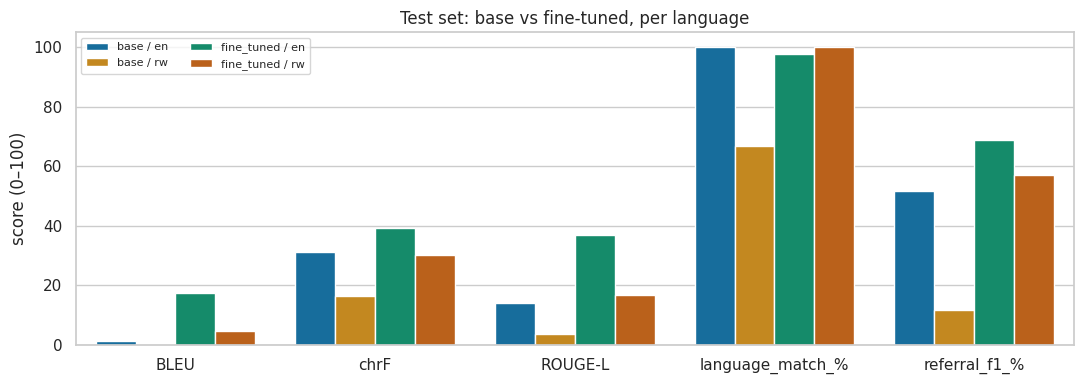

In [19]:
headline = comparison.query("split == 'test' and group == 'all'").set_index("metric")
for metric in ["ROUGE-L", "chrF", "BLEU", "perplexity", "language_match_%", "referral_f1_%"]:
    row = headline.loc[metric]
    verdict = "meets the 10% target" if row["improvement_%"] >= 10 else "below 10%"
    print(f"{metric:>18}: {row['base']:7.2f} -> {row['fine_tuned']:7.2f}   {row['improvement_%']:+6.1f}%   {verdict}")

fig, ax = plt.subplots(figsize=(11, 4))
plot_metrics = ["BLEU", "chrF", "ROUGE-L", "language_match_%", "referral_f1_%"]
scores = (comparison.query("split == 'test' and group != 'all' and metric in @plot_metrics")
          .melt(id_vars=["group", "metric"], value_vars=["base", "fine_tuned"], var_name="model"))
scores["model / language"] = scores["model"] + " / " + scores["group"]
sns.barplot(data=scores, x="metric", y="value", hue="model / language", ax=ax)
ax.set(title="Test set: base vs fine-tuned, per language", xlabel="", ylabel="score (0–100)")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "test_scores.png", dpi=150)
plt.show()

### 6.2 Safety behaviour as a classification

Rows are what the reference answer does, columns what the model does. A good model stays on the diagonal: it refers when it should, and gives practical advice otherwise.

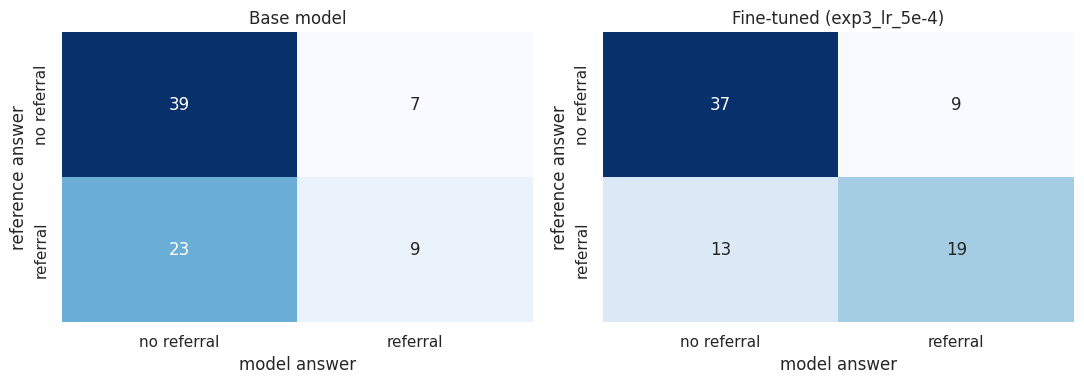

,group,base,fine_tuned,improvement_%,split
metric,,,,,
referral_accuracy_%,all,61.5,71.8,16.7,test
referral_precision_%,all,56.2,67.9,20.6,test
referral_recall_%,all,28.1,59.4,111.1,test
referral_f1_%,all,37.5,63.3,68.9,test
danger_referral_rate_%,all,16.7,58.3,250.0,test


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (title, result) in zip(axes, [("Base model", base["test"]), (f"Fine-tuned ({BEST_EXPERIMENT})", tuned["test"])]):
    matrix = pd.crosstab(result.predictions["reference_refers"], result.predictions["prediction_refers"]) \
        .reindex(index=[False, True], columns=[False, True], fill_value=0)
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["no referral", "referral"], yticklabels=["no referral", "referral"])
    ax.set(title=title, xlabel="model answer", ylabel="reference answer")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "referral_confusion.png", dpi=150)
plt.show()
display(headline.loc[[m for m in headline.index if m.startswith(("referral", "danger"))]].round(1))

### 6.3 Robustness to rewording

In [21]:
robustness = comparison.query("group == 'all' and metric in ['ROUGE-L', 'chrF', 'BLEU']") \
    .pivot(index="metric", columns="split", values="fine_tuned").round(2)
robustness["drop_on_paraphrases_%"] = (100 * (robustness["test"] - robustness["paraphrases"]) / robustness["test"]).round(1)
display(robustness)

split,paraphrases,test,drop_on_paraphrases_%
metric,,,
BLEU,13.06,11.76,-11.1
ROUGE-L,27.50,27.53,0.1
chrF,35.98,34.51,-4.3


## 7. Qualitative comparison

Scores do not show whether an answer is safe, practical and natural. Below are the same test questions answered by the base model and the fine-tuned model, one per language and category. All answers are in `outputs/qualitative_test.csv`.

In [22]:
side_by_side = base["test"].predictions[["id", "lang", "category", "question", "reference", "prediction"]] \
    .rename(columns={"prediction": "base_answer"}) \
    .merge(tuned["test"].predictions[["id", "prediction"]].rename(columns={"prediction": "fine_tuned_answer"}), on="id")
side_by_side.to_csv(OUTPUT_DIR / "qualitative_test.csv", index=False)

sample = side_by_side.groupby(["lang", "category"]).head(1).groupby("lang").head(4)
for _, row in sample.iterrows():
    print("=" * 110)
    print(f"[{row['lang']} | {row['category']}]  {row['question']}\n")
    print(f"REFERENCE:  {row['reference']}\n")
    print(f"BASE:       {row['base_answer']}\n")
    print(f"FINE-TUNED: {row['fine_tuned_answer']}\n")

[en | safety_redirect]  What are the life-threatening dangers for a severely malnourished child?

REFERENCE:  Severely malnourished children can quickly develop low blood sugar, become too cold, become dehydrated, or get a serious infection. Warning signs are: very sleepy or hard to wake, cold hands and feet, not able to drink or breastfeed, vomiting everything, fast breathing, or convulsions. If you see any of these, go to the nearest health centre or hospital immediately. Keep the child warm and keep breastfeeding on the way.

BASE:       The life-threatening dangers for a severely malnourished child include severe anemia, which can lead to weakness, fatigue, and difficulty in performing daily activities. Additionally, they may experience problems with their immune system, leading to frequent infections. Severe dehydration is another significant risk, as the body's ability to regulate fluid balance is compromised, potentially resulting in organ failure if not addressed promptly. Last

### 7.1 Error analysis: how the Kinyarwanda answers fail

Reading the Kinyarwanda answers shows failures the scores hide: answers that **loop** on one phrase, **echo** the question, slip into a **generic food list**, or answer a **different question**. `scripts/failure_analysis.py` finds loops and echoes automatically and writes a review sheet (`data/QA_data/review/failure_review.xlsx`) where a native speaker labels the rest. Below: the automatic counts for this model (labels from the reviewed sheet are used where they exist).

In [ ]:
!python scripts/failure_analysis.py --predictions {OUTPUT_DIR / "qualitative_test.csv"}
display(pd.read_csv("outputs/failure_summary.csv", index_col=0))

### 7.2 The full app pipeline: Kinyarwanda from reviewed answers only

The model answers English well but not Kinyarwanda (7.1), so **the app shows Kinyarwanda only from answers approved by a native speaker** (design and evidence in `docs/kinyarwanda.md`):

1. **Danger signs** get a fixed referral message (the model is not called).
2. **Reviewed answer:** a question that matches a reviewed pair (same foods, illnesses and ages) gets that pair's answer word for word.
3. **"Did you mean…?":** otherwise the app says it has no checked answer and offers up to three reviewed questions; the caregiver taps the one that fits.
4. **English** is answered by the fine-tuned model.

**Fair evaluation.** The similarity threshold for answering directly is chosen on the validation split. *Reworded* questions are the held-out paraphrases (their wording is not indexed); *new* questions are asked against an index of training pairs only, so any match is a mistake. `reworded_answered_or_suggested_%` is what a caregiver gets: the right reviewed answer directly or one tap away.

In [ ]:
from nutriassist.assistant import NutritionAssistant
from nutriassist.evaluation.pipeline import (PipelineChatModel, choose_threshold, knowledge_for, matching_study,
                                             threshold_table)
from nutriassist.translation import NllbTranslator, TermAwareTranslator

matching_val = threshold_table(matching_study("val", dataset.paraphrases))
THRESHOLD = choose_threshold(matching_val)
matching_test = threshold_table(matching_study("test", dataset.paraphrases), [THRESHOLD])
matching_test.to_csv(OUTPUT_DIR / "matching_test.csv", index=False)
print(f"Similarity threshold chosen on val: {THRESHOLD}")
display(matching_test.round(1))

**Alternative that was evaluated and rejected: translation through English.** An unmatched Kinyarwanda question is translated to English with NLLB-200, answered by the model in English, and translated back, with known food and health terms written in the target language first. The cell below scores it against the model's own Kinyarwanda. Expect the overlap metrics to rise; a native speaker nevertheless judged the translated answers unusable (wrong topic, meaningless sentences), so the app does not use translation. The comparison shows why overlap metrics alone cannot validate advice.

In [ ]:
PIPELINE_TAG = f"pipeline_{BEST_EXPERIMENT}{DECODING_SUFFIX}_test"
if EvaluationResult.exists(PRED_DIR, PIPELINE_TAG):
    pipeline_test = EvaluationResult.load(PRED_DIR, PIPELINE_TAG)
else:
    chat_model = TransformersChatModel.from_pretrained(best["base_model"], ADAPTERS_DIR / BEST_EXPERIMENT,
                                                    settings=DECODING)
    assistant = NutritionAssistant(chat_model, knowledge=knowledge_for("test", threshold=THRESHOLD),
                                   translator=TermAwareTranslator(NllbTranslator(device="cuda")))
    pipeline = PipelineChatModel(assistant, "app pipeline")
    pipeline_test = evaluator.evaluate(pipeline, dataset.test, cache_path=PRED_DIR / f"{PIPELINE_TAG}_answers.jsonl")
    pipeline_test.save(PRED_DIR, PIPELINE_TAG)
    if pipeline.replies:
        display(pipeline.sources().value_counts().rename("answers").to_frame())
    del chat_model, assistant, pipeline
    free_gpu_memory()

pipeline_vs_model = compare(tuned["test"], pipeline_test).rename(columns={"base": "model_alone", "fine_tuned": "pipeline"})
pipeline_vs_model.to_csv(OUTPUT_DIR / "pipeline_vs_model.csv", index=False)
display(pipeline_vs_model.pivot(index="metric", columns="group", values=["model_alone", "pipeline", "improvement_%"]).round(1))

In [ ]:
answers = tuned["test"].predictions[["id", "lang", "question", "reference", "prediction"]] \
    .rename(columns={"prediction": "model_alone"}) \
    .merge(pipeline_test.predictions[["id", "prediction"]].rename(columns={"prediction": "pipeline"}), on="id")
answers.to_csv(OUTPUT_DIR / "pipeline_answers_test.csv", index=False)
for _, row in answers[answers["lang"] == "rw"].head(4).iterrows():
    print("=" * 110)
    print(f"{row['question']}\n")
    print(f"REFERENCE:   {row['reference']}\n")
    print(f"MODEL ALONE: {row['model_alone']}\n")
    print(f"PIPELINE:    {row['pipeline']}\n")

## 8. Demo and export

### 8.1 Try the model (Gradio)

Run the cell and open the public link. Ask in English or Kinyarwanda. The full web app (FastAPI backend and Streamlit frontend) is in the repository's `app/` folder.

In [29]:
import gradio as gr

from nutriassist.prompts import build_messages

chat_model = TransformersChatModel.from_pretrained(best["base_model"], ADAPTERS_DIR / BEST_EXPERIMENT, settings=DECODING)

demo = gr.ChatInterface(
    fn=lambda message, history: chat_model.generate(build_messages(message)),
    title="NutriAssist-RW",
    description="Nutrition advice for caregivers of children under 5 in Rwanda, in English or Kinyarwanda. "
                "Not a substitute for a health worker: for danger signs, go to the health centre.",
    examples=["What foods should I give my 8-month-old baby?", "Umwana w'amezi 9 yarya iki?",
              "My child has diarrhoea and is very weak. What should I do?"],
)
demo.launch(share=True)

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ac0f7c07f54ac4e058.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


### 8.2 Export the model for the web app

The web app runs on ordinary computers without a GPU, so we:
1. **merge** the LoRA adapter into the base weights, giving one standalone model;
2. convert it to **GGUF**, the format `llama.cpp` uses for fast CPU inference;
3. save two sizes to Drive:

| File | Size | Use |
|---|---|---|
| `nutriassist-rw-q4_k_m.gguf` | about 1.0 GB | **recommended**: faster on a laptop CPU and quicker to download; small quality loss |
| `nutriassist-rw-q8_0.gguf` | about 1.6 GB | highest quality; for a stronger computer or the online deployment |

Both are made from a full-precision (16-bit) conversion, which gives better quality than shrinking the 8-bit file. If the session disconnects, run the cell again: files that already exist are kept.

In [ ]:
from peft import PeftModel
from transformers import AutoModelForCausalLM
import torch
import shutil
from pathlib import Path
from nutriassist.inference.transformers_model import load_tokenizer

# Ensure free_gpu_memory is imported
try:
    from nutriassist.training.finetune import free_gpu_memory
except ImportError:
    import gc
    def free_gpu_memory():
        gc.collect()
        torch.cuda.empty_cache()

if "demo" in globals():
    try:
        demo.close()
    except Exception:
        pass

chat_model = None
free_gpu_memory()

# Fallbacks for missing environment variables after a kernel restart
if "OUTPUT_DIR" not in globals():
    DRIVE_ROOT = Path("/content/drive/MyDrive")
    USE_DRIVE = DRIVE_ROOT.exists()
    OUTPUT_DIR = DRIVE_ROOT / "NutriAssist-RW" / "outputs" if USE_DRIVE else Path("/content/NutriAssist-RW/outputs")

if "ADAPTERS_DIR" not in globals():
    ADAPTERS_DIR = OUTPUT_DIR / "adapters"

if "BEST_EXPERIMENT" not in globals() or "best" not in globals():
    # After a kernel restart: re-read the choice made in section 5.2 from the saved results.
    from nutriassist.training.dataset import QADataset
    from nutriassist.training.experiments import ExperimentRunner
    _runner = ExperimentRunner(QADataset.load(Path("/content/NutriAssist_Capstone/data/QA_data/processed")), OUTPUT_DIR)
    BEST_EXPERIMENT = _runner.best("val_rw_chrF", "val_loss")
    best = _runner.results().set_index("experiment").loc[BEST_EXPERIMENT]

MERGED_DIR = Path("/content/nutriassist-merged")
F16_PATH = Path("/content/nutriassist-rw-f16.gguf")      # temporary (3 GB), not saved to Drive
GGUF_FILES = {kind: OUTPUT_DIR / f"nutriassist-rw-{kind}.gguf" for kind in ("q4_k_m", "q8_0")}

# The files are re-exported when the final model changes (e.g. after new experiments).
SOURCE_FILE = OUTPUT_DIR / "gguf_source.txt"
if SOURCE_FILE.exists() and SOURCE_FILE.read_text().strip() != BEST_EXPERIMENT:
    print(f"The saved GGUF files come from {SOURCE_FILE.read_text().strip()}; re-exporting {BEST_EXPERIMENT}")
    for stale in [*GGUF_FILES.values(), F16_PATH]:
        stale.unlink(missing_ok=True)
    shutil.rmtree(MERGED_DIR, ignore_errors=True)

if not all(path.exists() for path in GGUF_FILES.values()):
    if not F16_PATH.exists():
        full_precision = AutoModelForCausalLM.from_pretrained(best["base_model"], dtype=torch.float16, device_map={"": 0})
        merged = PeftModel.from_pretrained(full_precision, ADAPTERS_DIR / BEST_EXPERIMENT).merge_and_unload()
        merged.save_pretrained(MERGED_DIR)
        load_tokenizer(ADAPTERS_DIR / BEST_EXPERIMENT).save_pretrained(MERGED_DIR)
        del merged, full_precision
        free_gpu_memory()
        if not Path("/content/llama.cpp").exists():
            !git clone -q --depth 1 https://github.com/ggml-org/llama.cpp /content/llama.cpp
        !pip install -q /content/llama.cpp/gguf-py
        !python /content/llama.cpp/convert_hf_to_gguf.py {MERGED_DIR} --outfile {F16_PATH} --outtype f16

    !pip install -q llama-cpp-python --extra-index-url https://abetlen.github.io/llama-cpp-python/whl/cpu
    from nutriassist.inference.quantize import quantize_gguf

    for kind, path in GGUF_FILES.items():
        if not path.exists():
            print(f"Making {path.name}...")
            quantize_gguf(F16_PATH, path, kind)

SOURCE_FILE.write_text(BEST_EXPERIMENT)
for path in GGUF_FILES.values():
    print(f"{path.name}: {path.stat().st_size / 1024**3:.2f} GB (from {BEST_EXPERIMENT})")

### 8.3 Check the exported model on a CPU

The web app will run the GGUF file on a CPU, so test exactly that here: the smaller model answers through the same safety pipeline as the app. Colab's CPU has only 2 cores, so each answer takes a while; a laptop is usually faster.

In [6]:
import time
from nutriassist.assistant import NutritionAssistant
from nutriassist.inference.base import GenerationSettings
from nutriassist.inference.llamacpp_model import LlamaCppChatModel

# The app reads the penalty from NUTRIASSIST_REPETITION_PENALTY; use the value chosen in 5.3.
penalty = DECODING.repetition_penalty if "DECODING" in globals() else GenerationSettings().repetition_penalty
cpu_model = LlamaCppChatModel.from_file(GGUF_FILES["q4_k_m"],
                                        settings=GenerationSettings(repetition_penalty=penalty, batch_size=1))
print(f"Set NUTRIASSIST_REPETITION_PENALTY={penalty} for the web app")
cpu_assistant = NutritionAssistant(cpu_model)
for question in ["What foods should I give my 8-month-old baby?",
                 "Umwana w'amezi 9 yarya iki?",
                 "My child is having a seizure. What should I do?"]:
    start = time.perf_counter()
    reply = cpu_assistant.ask(question)
    print(f"Q: {question}\n[{reply.source.value}, {time.perf_counter() - start:.1f} s]\n{reply.answer}\n")
del cpu_assistant, cpu_model

Q: What foods should I give my 8-month-old baby?
[model, 3.9 s]
From 6 months, give smooth, thick sorghum or maize porridge thickened with groundnut paste or a little oil, and add mashed banana, avocado or milk. Mix beans with rice or potatoes, and give mashed pumpkin or sweet potato with soft bread. By 8 months, most children can eat family food, thick chopped pieces cooked until soft, like ibitoki with beans or ibirayi with rice.

Q: Umwana w'amezi 9 yarya iki?
[model, 5.0 s]
Igikoma cy'amezi 9 ni ibishyimbo: umwijima (ibinyampeke, imbuto, ibirayi), amashu (isambaza, amata), amasaka (ibinyampeke, imbuto, amavuta), inyama (ibijumba, ibigori, ibirayi), amafi (ibishyimbo, ibishyimbye, ibirayi), ibitoki (ibinyampeke, imbuto, amata), ibirayi n'umuceri. Jyayo y'amezi 9 ni ifunguro ryoseye ku mwana wawe.

Q: My child is having a seizure. What should I do?
[safety_rule, 0.0 s]
⚠️ This may be a danger sign: convulsions or fits.

Take your child to the nearest health centre or hospital **now**

### 8.4 Download the model to your computer

1. Open https://drive.google.com, then *My Drive → NutriAssist-RW → outputs*.
2. Right-click **`nutriassist-rw-q4_k_m.gguf`** → *Download*. Google says it cannot scan large files for viruses: click *Download anyway*.
   On a slow connection, if the download stops, open Chrome's downloads page (Ctrl+J) and click *Resume*.
3. Move the file into the **`models/`** folder of the project on your computer (create the folder if it is missing).
   Git ignores this folder: the file is too large for GitHub (limit 100 MB), so it stays on your computer.
4. Start the app with `python scripts/run_local.py`. The sidebar should say *Assistant is online* and **not** *Demo mode*.

Also download these small files for the report and the README: `experiment_table.csv`, `final_comparison.csv`, `qualitative_test.csv` and the `.png` figures.



```
# This is formatted as code
```

### 8.5 publish to Hugging Face Hub

Needed for the online deployment (see `docs/deployment.md`): the Hugging Face Space downloads the model from here. Set `HF_REPO` (for example `"your-username/nutriassist-rw"`) and run the cell; you will be asked for a Hugging Face **write** token. Uploading from Colab is much faster than uploading from your own connection.

In [10]:
HF_REPO = None

if HF_REPO:
    from huggingface_hub import HfApi, notebook_login

    notebook_login()
    api = HfApi()
    api.create_repo(HF_REPO, exist_ok=True)
    api.upload_folder(folder_path=str(ADAPTERS_DIR / BEST_EXPERIMENT), repo_id=HF_REPO, path_in_repo="adapter")
    for path in GGUF_FILES.values():
        api.upload_file(path_or_fileobj=str(path), path_in_repo=path.name, repo_id=HF_REPO)
    print(f"Uploaded to https://huggingface.co/{HF_REPO}")

In [11]:
from huggingface_hub import HfApi, login

# 1. Login to your Hugging Face account securely
login()

# Define your repository ID
HF_REPO = "pauline-ish/NutritionAssistant_RW"
api = HfApi()

print(f"Target repository: https://huggingface.co/{HF_REPO}")

# 2. Upload only the fine-tuned adapter folder
print("Uploading fine-tuned adapter...")
api.upload_folder(
    folder_path=str(ADAPTERS_DIR / BEST_EXPERIMENT),
    repo_id=HF_REPO,
    path_in_repo="adapter"
)

# 3. Upload only the finalized GGUF files for CPU deployment
print("Uploading GGUF models...")
for path in GGUF_FILES.values():
    if path.exists():
        print(f"Uploading {path.name}...")
        api.upload_file(
            path_or_fileobj=str(path),
            path_in_repo=path.name,
            repo_id=HF_REPO
        )

print("\n=== UPLOAD COMPLETE! ===")
print(f"Your model is cleanly deployed and ready at: https://huggingface.co/{HF_REPO}")

Target repository: https://huggingface.co/pauline-ish/NutritionAssistant_RW
Uploading fine-tuned adapter...
Uploading GGUF models...
Uploading nutriassist-rw-q4_k_m.gguf...


Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...utriassist-rw-q4_k_m.gguf:   0%|          |  548kB /  986MB            

Validating                    :           |   0%            

...

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  .../nutriassist-rw-q8_0.gguf:   0%|          | 5.91MB / 1.65GB            

Validating                    :           |   0%            


=== UPLOAD COMPLETE! ===
Your model is cleanly deployed and ready at: https://huggingface.co/pauline-ish/NutritionAssistant_RW


In [12]:
# Clean up temporary giant files so that Colab's 'Save a copy in GitHub' works
import os
from pathlib import Path

# 1. Delete the massive 3.1 GB f16 file from local storage
f16_path = Path("/content/nutriassist-rw-f16.gguf")
if f16_path.exists():
    print(f"Removing temporary giant file: {f16_path.name} ({f16_path.stat().st_size / 1024**3:.2f} GB)")
    f16_path.unlink()
else:
    print("f16 file already cleaned up.")

# 2. Clear any local GGUF outputs in the local VM folder to prevent GitHub sync errors
# (Don't worry, your copies are safely uploaded to Hugging Face and saved in Google Drive!)
local_gguf_dir = Path("/content/NutriAssist-RW/outputs")
if local_gguf_dir.exists():
    for gguf_file in local_gguf_dir.glob("*.gguf"):
        print(f"Removing local GGUF copy: {gguf_file.name} ({gguf_file.stat().st_size / 1024**3:.2f} GB)")
        gguf_file.unlink()

print("\n=== CLEANUP COMPLETE ===")
print("Your workspace is clean! You can now safely use 'File -> Save a copy in GitHub'.")

Removing temporary giant file: nutriassist-rw-f16.gguf (2.88 GB)
Removing local GGUF copy: nutriassist-rw-q4_k_m.gguf (0.92 GB)
Removing local GGUF copy: nutriassist-rw-q8_0.gguf (1.53 GB)

=== CLEANUP COMPLETE ===
Your workspace is clean! You can now safely use 'File -> Save a copy in GitHub'.


In [9]:
# 1. Mount Google Drive
from google.colab import drive
from pathlib import Path
import shutil

try:
    print("Mounting Google Drive...")
    drive.mount("/content/drive", force_remount=True)

    local_outputs = Path("/content/NutriAssist-RW/outputs")
    drive_destination = Path("/content/drive/MyDrive/NutriAssist-RW/outputs")

    if local_outputs.exists():
        print(f"Creating destination directory in Drive: {drive_destination}")
        drive_destination.mkdir(parents=True, exist_ok=True)

        print("Copying your generated GGUF models and evaluation results to Google Drive...")
        # Use shutil to copy entire directory contents
        for item in local_outputs.glob("*"):
            dest_item = drive_destination / item.name
            if item.is_dir():
                if dest_item.exists():
                    shutil.rmtree(dest_item)
                shutil.copytree(item, dest_item)
            else:
                shutil.copy2(item, dest_item)
        print("\n=== SUCCESS! ===")
        print("All files have been successfully copied! You can now find the 'NutriAssist-RW' folder inside your Google Drive.")
    else:
        print("Error: No local outputs found at /content/NutriAssist-RW/outputs. Please ensure the notebook has run to completion.")
except Exception as e:
    print(f"An error occurred while mounting or copying files: {e}")

Mounting Google Drive...
Mounted at /content/drive
Creating destination directory in Drive: /content/drive/MyDrive/NutriAssist-RW/outputs
Copying your generated GGUF models and evaluation results to Google Drive...

=== SUCCESS! ===
All files have been successfully copied! You can now find the 'NutriAssist-RW' folder inside your Google Drive.


## Files saved to Drive (`MyDrive/NutriAssist-RW/outputs/`)

| File | Contents |
|---|---|
| `experiment_table.csv`, `experiments.csv` | Settings, training time, peak GPU memory, losses and validation scores of every run |
| `final_comparison.csv` | Base vs fine-tuned on test and paraphrases, per language, with % improvement |
| `qualitative_test.csv` | Every test question with the reference, base and fine-tuned answers |
| `predictions/` | All generated answers and scores |
| `adapters/<experiment>/` | LoRA adapters, training logs and settings |
| `*.png` | The figures above, ready for the report |
| `nutriassist-rw-q4_k_m.gguf`, `nutriassist-rw-q8_0.gguf` | The fine-tuned model for CPU inference in the web app (put one in the project's `models/` folder) |